In [11]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
import intake
import pandas as pd
import os

In [3]:
# URL to the CMIP6 downscaling plans CSV file (Jesus Table)
url = "https://raw.githubusercontent.com/WCRP-CORDEX/simulation-status/main/CMIP6_downscaling_plans.csv"
df = pd.read_csv(url)
df.head()


,domain_id,institution_id,contact,source_id,driving_source_id,driving_variant_label,driving_experiment_id,status,estimated_completion_date,comments
0,AFR-12,CLMcom-CMCC,M. Raffa / M. Adinolfi / A. Campanale,ICON-CLM-202604-1-1,ERA5,NaN,evaluation,running,2026-10,NaN
1,AFR-12,GERICS,C. Teichmann,REMO2020-2-2,ERA5,NaN,evaluation,planned,2026-09,#CORDEX-CORE
2,AFR-12,GERICS,C. Teichmann,REMO2020-2-2,EC-Earth3-Veg,r1i1p1f1,historical,planned,2026-12,#CORDEX-CORE
3,AFR-12,GERICS,C. Teichmann,REMO2020-2-2,EC-Earth3-Veg,r1i1p1f1,ssp370,planned,2026-12,#CORDEX-CORE
4,AFR-12,GERICS,C. Teichmann,REMO2020-2-2,MPI-ESM1-2-HR,r1i1p1f1,historical,planned,2026-12,#CORDEX-CORE


In [ ]:
df['driving_source_id'].unique()
df['domain_id'].unique()

In [4]:
df_eur12=df[df['domain_id']=='EUR-12']
df_eur12=df_eur12[df_eur12['institution_id']!='EURO-CORDEX']
df_eur12.head()
df_eur12_small = df_eur12[['institution_id', 'source_id', 'driving_source_id', 'driving_variant_label', 'driving_experiment_id']]

In [ ]:
df_eur12

In [5]:
df_eur12_small=df_eur12_small[df_eur12_small['driving_source_id']!='ERA5']
df_eur12_small
df_eur12_small.to_csv("df_eur12_small.csv", index=False)

In [6]:
#'available in Jülich'

cat = intake.open_esm_datastore("https://raw.githubusercontent.com/euro-cordex/jsc-cordex-catalog/refs/heads/main/CORDEX-CMIP6-JSC.json")
cat#.keys()


,unique
project_id,3
mip_era,2
activity_id,3
domain_id,3
institution_id,33
driving_source_id,12
driving_experiment_id,9
driving_variant_label,8
source_id,35
version_realization,6


In [7]:


# ------------------------------------------------------------------
# CSV mit den Downscaling-Plänen laden
# ------------------------------------------------------------------

df = pd.read_csv("df_eur12_small.csv")

# ------------------------------------------------------------------
# Intake-ESM Catalog öffnen
# ------------------------------------------------------------------

cat = intake.open_esm_datastore("https://raw.githubusercontent.com/euro-cordex/jsc-cordex-catalog/refs/heads/main/CORDEX-CMIP6-JSC.json")
cdf = cat.df

# ------------------------------------------------------------------
# Spalten, die zusammen eine Modellkette beschreiben
# ------------------------------------------------------------------

match_cols = [
    "institution_id",
    "source_id",
    "driving_source_id",
    "driving_variant_label",
    "driving_experiment_id",
]

# ------------------------------------------------------------------
# Benötigte Variablen
# ------------------------------------------------------------------

required_vars = {"tas", "pr"}
#required_vars = {"tas", "pr", "tasmin", "tasmax"}

# ------------------------------------------------------------------
# Nur Tagesdaten betrachten
# ------------------------------------------------------------------

cdf_day = cdf[cdf["frequency"] == "day"]

# ------------------------------------------------------------------
# Welche Variablen sind für jede Modellkette vorhanden?
# ------------------------------------------------------------------

available = (
    cdf_day.groupby(match_cols)["variable_id"]
    .agg(lambda x: set(x))
    .reset_index()
)

# ------------------------------------------------------------------
# Sind alle benötigten Variablen vorhanden?
# ------------------------------------------------------------------

available["in_catalog"] = available["variable_id"].apply(
    lambda x: required_vars.issubset(set(x))
)

# ------------------------------------------------------------------
# Welche Variablen fehlen?
# ------------------------------------------------------------------

available["missing_variables"] = available["variable_id"].apply(
    lambda x: ",".join(sorted(required_vars - set(x))))


# ------------------------------------------------------------------
# Mit der ursprünglichen CSV verknüpfen
# ------------------------------------------------------------------

df = df.merge(
    available,
    on=match_cols,
    how="left"
)

# ------------------------------------------------------------------
# Kombination nicht im Katalog gefunden
# ------------------------------------------------------------------

df["in_catalog"] = df["in_catalog"].fillna(False)

df["missing_variables"] = df["missing_variables"].fillna(
    "combination_not_found"
)

# ------------------------------------------------------------------
# True/False zu yes/no
# ------------------------------------------------------------------

df["in_catalog"] = df["in_catalog"].map(
    {True: "yes", False: "no"}
)

# ------------------------------------------------------------------
# Speichern
# ------------------------------------------------------------------

df.to_csv(
    "CMIP6_downscaling_plans_checked.csv",
    index=False
)

print(df["in_catalog"].value_counts())

in_catalog
no     106
yes     72
Name: count, dtype: int64


In [8]:
df = pd.read_csv("CMIP6_downscaling_plans_checked.csv")
df

,institution_id,source_id,driving_source_id,driving_variant_label,driving_experiment_id,variable_id,in_catalog,missing_variables
0,AUTH,WRF451Q,MPI-ESM1-2-HR,r1i1p1f1,historical,NaN,no,combination_not_found
1,AUTH,WRF451Q,MPI-ESM1-2-HR,r1i1p1f1,ssp126,NaN,no,combination_not_found
2,BCCR-UCAN,WRF451Q,NorESM2-MM,r1i1p1f1,historical,['tasmin' 'huss' 'psl' 'pr' 'tas' 'clt' 'tasma...,yes,NaN
3,BCCR-UCAN,WRF451Q,NorESM2-MM,r1i1p1f1,ssp126,['tasmin' 'huss' 'psl' 'pr' 'tas' 'clt' 'tasma...,yes,NaN
4,BCCR-UCAN,WRF451Q,NorESM2-MM,r1i1p1f1,ssp370,['tasmin' 'huss' 'psl' 'pr' 'tas' 'clt' 'tasma...,yes,NaN
...,...,...,...,...,...,...,...,...
173,RMIB-UGent,ALARO1-SFX,EC-Earth3-Veg,r1i1p1f1,ssp585,NaN,no,combination_not_found
174,CYI,WRF461U,EC-Earth3-Veg,r1i1p1f1,historical,NaN,no,combination_not_found
175,CYI,WRF461U,EC-Earth3-Veg,r1i1p1f1,ssp370,NaN,no,combination_not_found
176,CLMcom-GUF,CCLM5-0-9-NEMOMED12-3-6,EC-Earth3-Veg,r12i1p1f1,historical,NaN,no,combination_not_found


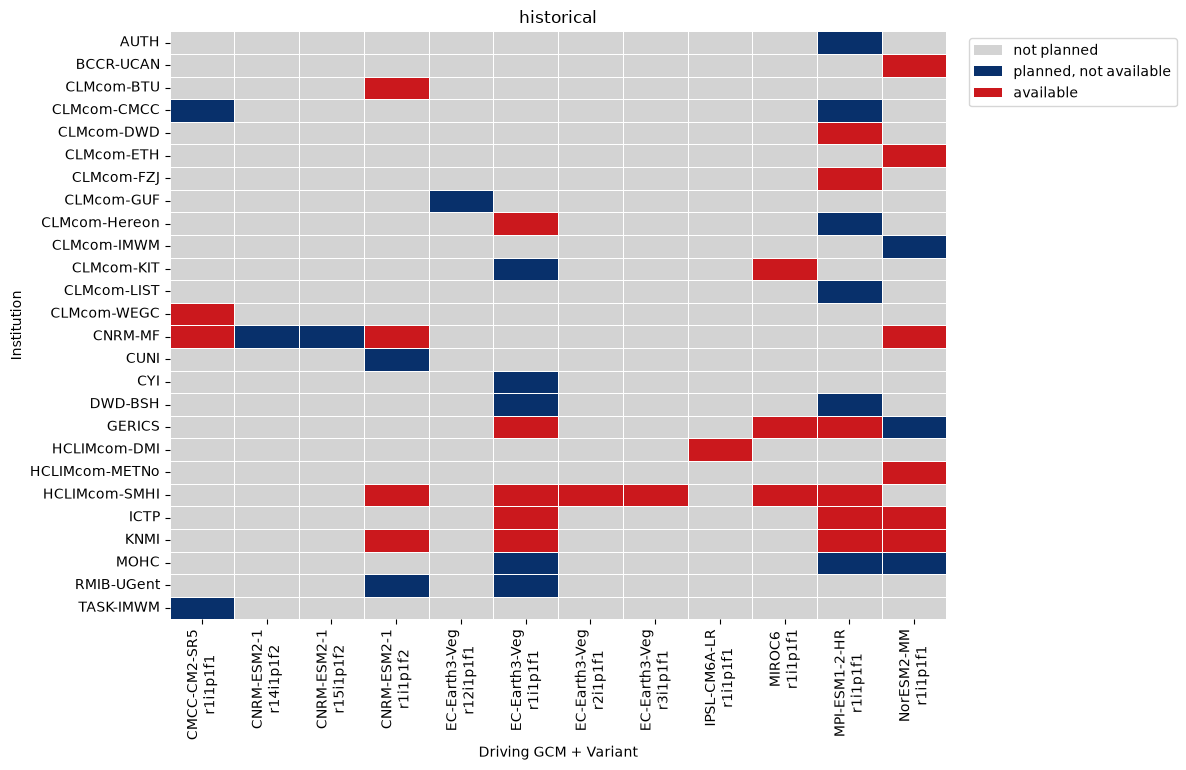

<Figure size 640x480 with 0 Axes>

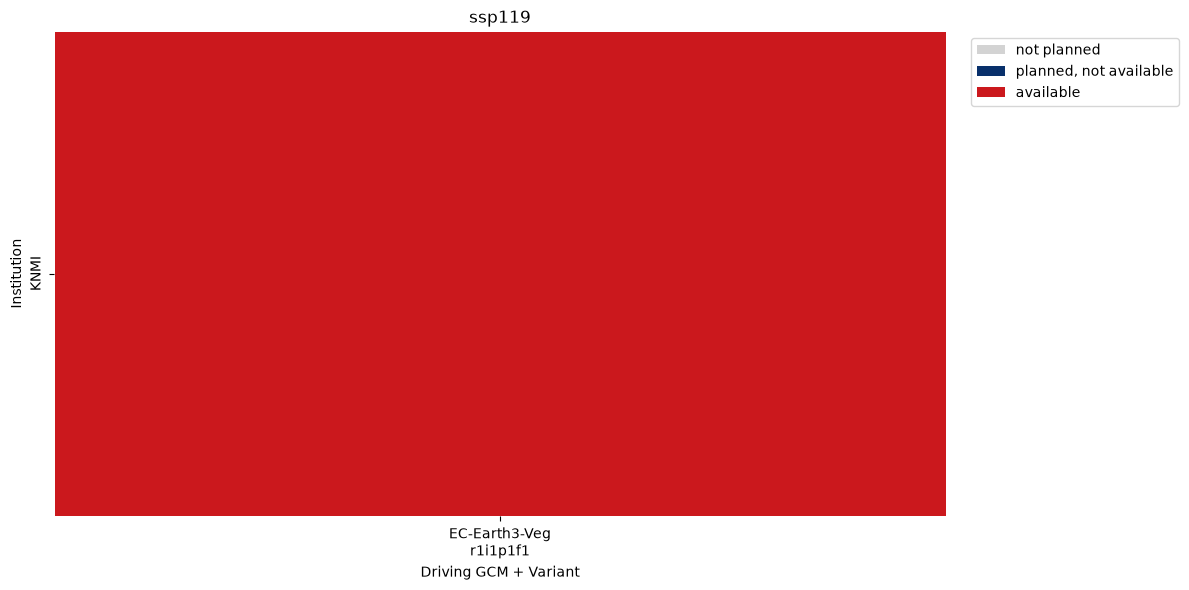

<Figure size 640x480 with 0 Axes>

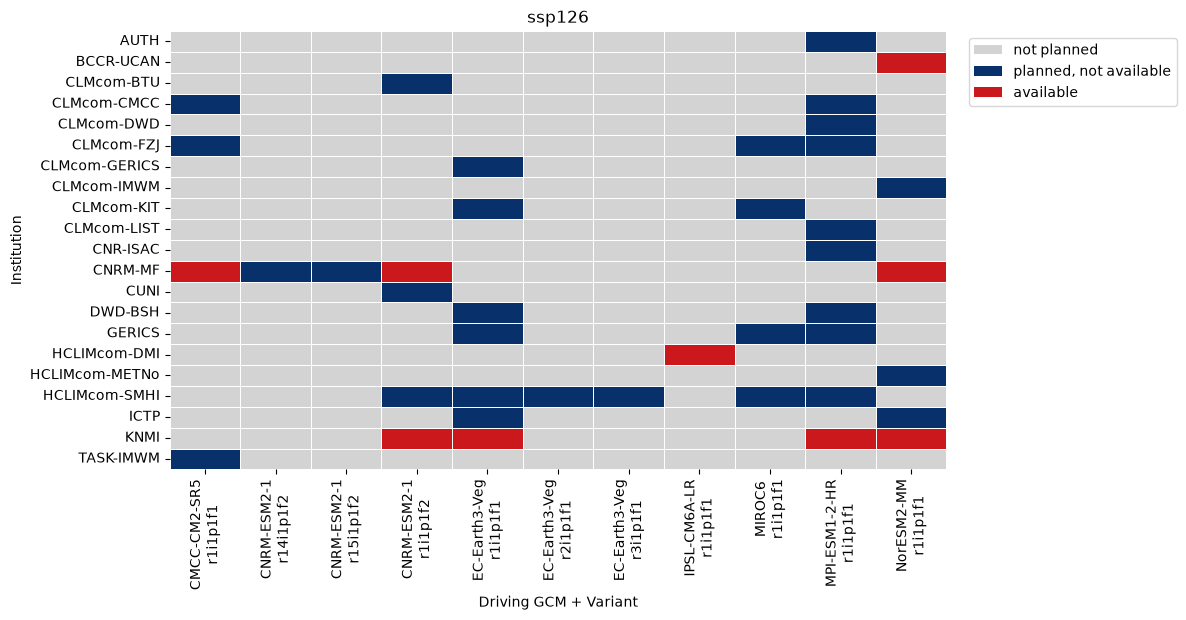

<Figure size 640x480 with 0 Axes>

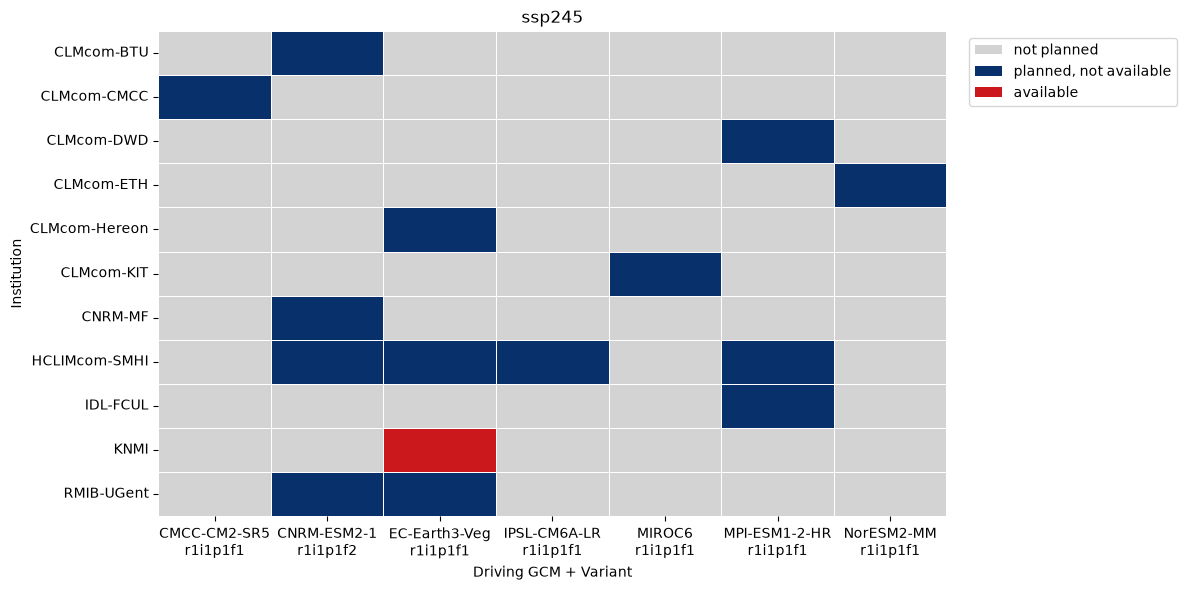

<Figure size 640x480 with 0 Axes>

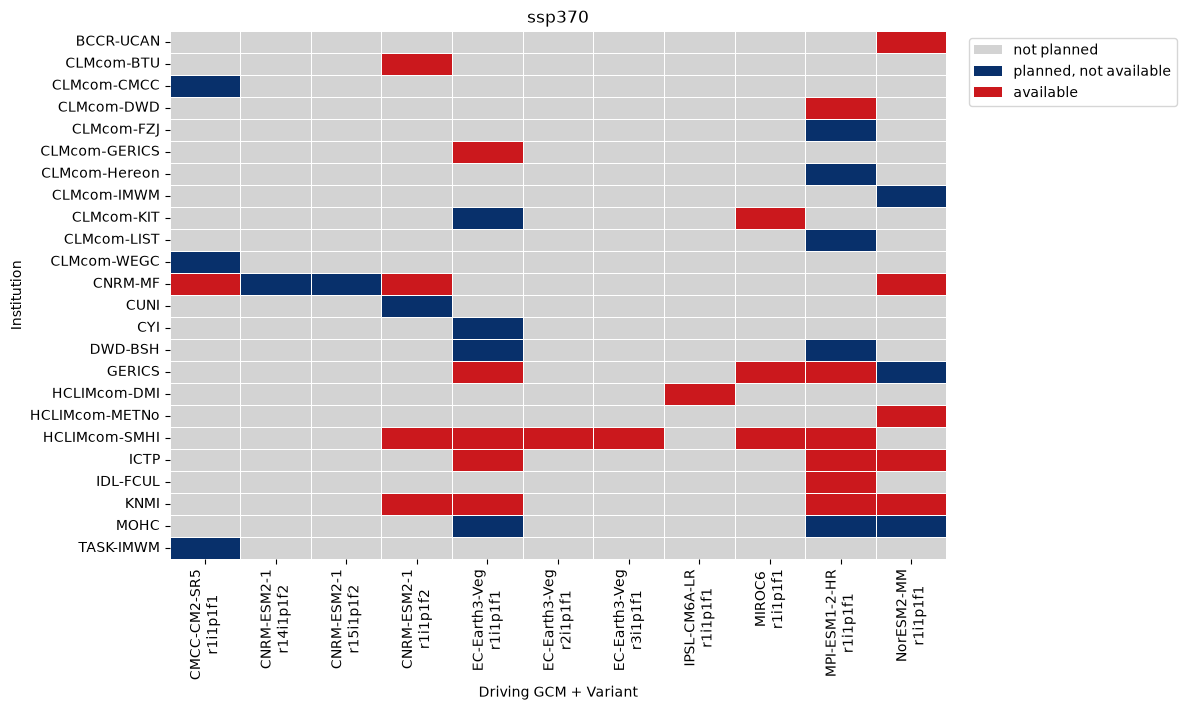

<Figure size 640x480 with 0 Axes>

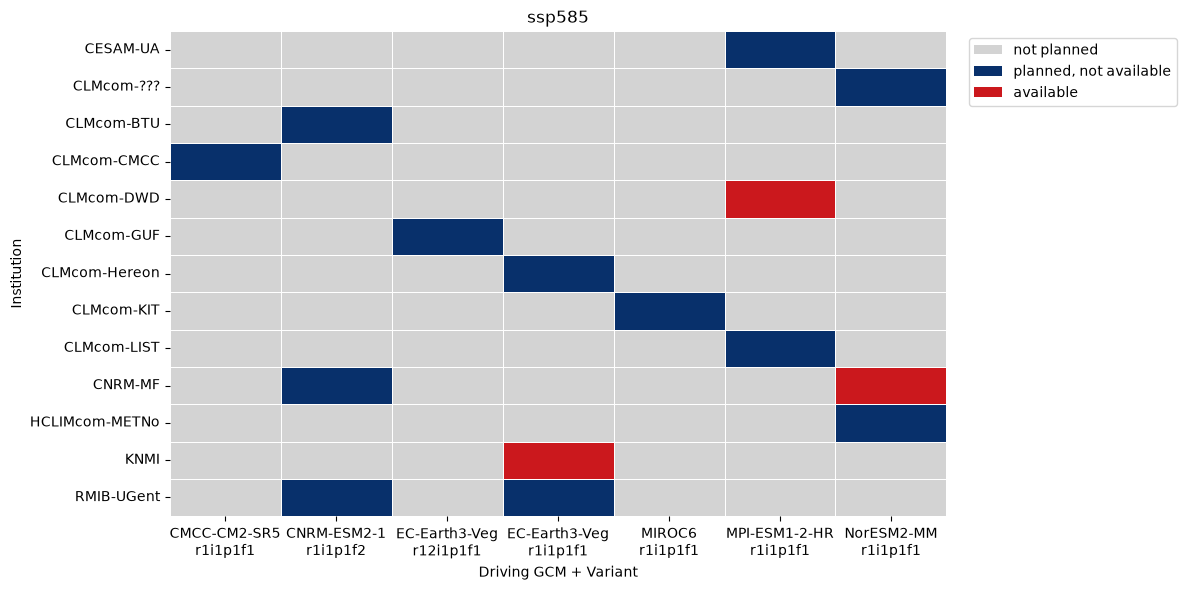

<Figure size 640x480 with 0 Axes>

In [18]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# csv laden
df = pd.read_csv("CMIP6_downscaling_plans_checked.csv")

# Kombination für x-Achse erzeugen
df["gcm_variant"] = (
    df["driving_source_id"]
    + "\n"
    + df["driving_variant_label"]
)

# yes/no in 1/0 umwandeln
df["value"] = df["in_catalog"].map({
    "yes": 2,
    "no": 1
})

# Farben:
from matplotlib.colors import ListedColormap

cmap = ListedColormap([
    "lightgrey",  # 0 = not in CSV
    "#08306B",    # 1 = no (blue)
    "#CB181D",    # 2 = yes (red)
])


for experiment in sorted(df["driving_experiment_id"].unique()):

    sub = df[df["driving_experiment_id"] == experiment]

    heatmap_df = sub.pivot_table(
        index="institution_id",
        columns="gcm_variant",
        values="value",
        aggfunc="max",
        fill_value=0
    )

    plt.figure(
        figsize=(
            max(12, len(heatmap_df.columns) * 0.4),
            max(6, len(heatmap_df.index) * 0.3)
        )
    )

    sns.heatmap(
        heatmap_df,
        cmap=cmap,
        cbar=False,
        linewidths=0.5,
        linecolor="white",
        vmin=0,
        vmax=2
    )

    plt.title(f"{experiment}")
    plt.xlabel("Driving GCM + Variant")
    plt.ylabel("Institution")

    from matplotlib.patches import Patch

    legend_elements = [
        Patch(facecolor="lightgrey", label="not planned"),
        Patch(facecolor="#08306B", label="planned, not available"),
        Patch(facecolor="#CB181D", label="available"),
    ]

    plt.legend(
        handles=legend_elements,
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.tight_layout()
    plt.show()

    plt.savefig(
        f"heatmap_{experiment}.png",
        dpi=300,
        bbox_inches="tight"
    )